# Architectures Based on RNNs
## Which signal came first?

Two sequences contain the same tokens in different orders. Can a recurrent model report which signal it saw first, even after several unrelated readings?

This notebook accompanies the PowerPoint. It runs on a CPU, generates its own data, and includes saved outputs. In Jupyter or VS Code, select a Python kernel and choose **Restart Kernel and Run All**. Install the dependencies in that environment once with **python -m pip install torch matplotlib ipykernel**. For a local Jupyter interface, also install **jupyterlab**.

Both plots are also saved beside this notebook in `outputs/validation_loss.png` and `outputs/test_accuracy.png`. Rerunning a plot updates its PNG.

**Course connection.** Chapter 6, pp. 2–16, introduces recurrent states, gates, directionality and encoder–decoders. Its practice page (p. 17) covers sequence representations and variable lengths. The paired-signal experiment is an application chosen for this presentation.

In [1]:
from collections import Counter
from copy import deepcopy
from pathlib import Path
import random
import sys

import matplotlib
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.nn.utils.rnn import pack_padded_sequence, pad_sequence
from torch.utils.data import DataLoader

SEED = 27
BATCH = 48
EPOCHS = 10
WIDTH = 16
EMBED = 8
LEARNING_RATE = 0.008

# Jupyter and VS Code can start the kernel in the notebook folder or the project root.
presentation_dir = Path("RNN-Presentation")
output_dir = (presentation_dir if presentation_dir.is_dir() else Path.cwd()) / "outputs"

def save_result_figure(fig, filename):
    """Save the displayed figure under the PNG filename used in both reports."""
    output_dir.mkdir(parents=True, exist_ok=True)
    path = output_dir / filename
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Saved {path.parent.name}/{path.name}")

torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
torch.manual_seed(SEED)
print(f"Python {sys.version.split()[0]} | PyTorch {torch.__version__} | Matplotlib {matplotlib.__version__} | CPU")

Python 3.10.11 | PyTorch 2.14.1+cpu | Matplotlib 3.10.9 | CPU


## An order question that token counts cannot answer

Each sequence contains the signals **red** and **blue** exactly once. The label is the first signal. Each example has a partner with both signals swapped and every neutral token in its original position. Any deterministic classifier that sees only token counts must give the same answer to both partners. It therefore scores exactly 50% on complete pairs.

Generate a neutral prefix of 0–2 tokens, a gap of 1–3 between signals, and a tail of 2–10 tokens after the second signal. Reserve a second test condition with tails of 18–26 tokens. The generator keeps partners together and prevents duplicate examples across splits.

In [2]:
TOKENS = ["<pad>", "red", "blue", "tick", "tap", "hum", "ping"]
ID = {token: index for index, token in enumerate(TOKENS)}
LABELS = ["red first", "blue first"]
PAD = ID["<pad>"]
NEUTRAL = TOKENS[3:]

def make_split(pair_count, tail_range, seed, seen):
    rng = random.Random(seed)
    rows = []
    while len(rows) < pair_count * 2:
        prefix = rng.choices(NEUTRAL, k=rng.randint(0, 2))
        gap = rng.choices(NEUTRAL, k=rng.randint(1, 3))
        tail = rng.choices(NEUTRAL, k=rng.randint(*tail_range))
        red_first = tuple(prefix + ["red"] + gap + ["blue"] + tail)
        blue_first = tuple(prefix + ["blue"] + gap + ["red"] + tail)
        if red_first in seen or blue_first in seen:
            continue
        seen.update((red_first, blue_first))
        rows.extend([(red_first, 0), (blue_first, 1)])
    return rows

seen = set()
train = make_split(384, (2, 10), 101, seen)
valid = make_split(96, (2, 10), 102, seen)
test = make_split(128, (2, 10), 103, seen)
long_test = make_split(128, (18, 26), 104, seen)
splits = {"Train": train, "Validation": valid, "Test": test, "Long-tail test": long_test}
assert len(seen) == sum(map(len, splits.values()))
for name, rows in splits.items():
    assert all(Counter(a) == Counter(b) and (ya, yb) == (0, 1)
               for (a, ya), (b, yb) in zip(rows[::2], rows[1::2]))
    print(f"{name:15} {len(rows):4} sequences | {len(rows)//2:3} per class")
for tokens, label in train[:2]:
    print(" ".join(tokens), "=>", LABELS[label])

Train            768 sequences | 384 per class
Validation       192 sequences |  96 per class
Test             256 sequences | 128 per class
Long-tail test   256 sequences | 128 per class
ping ping red ping tap hum blue hum ping tap ping tap => red first
ping ping blue ping tap hum red hum ping tap ping tap => blue first


## Representing variable-length sequences

An integer ID selects a vocabulary entry. One-hot encoding gives each ID its own coordinate. A learned embedding instead looks up a trainable vector for each ID. Padding allows multiple lengths in one tensor. The recurrent layer receives the true lengths so that padding never becomes part of the final state.

Right truncation changes the input. In this example a cap of three loses the second signal; keeping only the last two tokens loses both. The scored experiment keeps every original token, including the entire tail in the longer test.

In [3]:
def encode(tokens, limit=None):
    tokens = tokens if limit is None else tokens[:limit]
    return torch.tensor([ID[t] for t in tokens], dtype=torch.long)

def collate(rows):
    sequences = [encode(tokens) for tokens, _ in rows]
    lengths = torch.tensor([len(seq) for seq in sequences])
    labels = torch.tensor([label for _, label in rows])
    return pad_sequence(sequences, batch_first=True, padding_value=PAD), lengths, labels

example = ("red", "tick", "tap", "blue", "hum", "ping")
example_ids = encode(example)
print("Vocabulary:", ID)
print("Integer IDs:", example_ids.tolist())
print("One-hot for red:", F.one_hot(example_ids[0], len(TOKENS)).tolist())
print("Embedding lookup shape:", tuple(nn.Embedding(len(TOKENS), EMBED)(example_ids).shape))
print("Right-truncated to three:", [TOKENS[i] for i in encode(example, limit=3)])
print("Only the last two:", list(example[-2:]))
padded, lengths, _ = collate([(example, 0), (("blue", "tap", "red"), 1)])
print("Padded batch:", padded.tolist(), "| True lengths:", lengths.tolist())

Vocabulary: {'<pad>': 0, 'red': 1, 'blue': 2, 'tick': 3, 'tap': 4, 'hum': 5, 'ping': 6}
Integer IDs: [1, 3, 4, 2, 5, 6]
One-hot for red: [0, 1, 0, 0, 0, 0, 0]
Embedding lookup shape: (6, 8)
Right-truncated to three: ['red', 'tick', 'tap']
Only the last two: ['hum', 'ping']
Padded batch: [[1, 3, 4, 2, 5, 6], [2, 4, 1, 0, 0, 0]] | True lengths: [6, 3]


## How a recurrent cell carries context

A vanilla recurrent neural network (RNN) reuses the same weights at every time step. With a zero initial state, its update is
$$h_t=\tanh(W_x x_t+W_h h_{t-1}+b).$$
A many-to-one classifier reads the final valid state. Backpropagation through time sends the loss gradient through each update. Repeated multiplications can shrink or amplify it. Norm clipping caps the total gradient norm before the optimizer step. Gates give information a learnable route across time.

| Cell | State passed to the next step | How information moves |
|---|---|---|
| Vanilla RNN | Hidden state $h_t$ | Recomputes the state with a tanh transformation. |
| Long short-term memory (LSTM) | Cell state $c_t$ and hidden state $h_t$ | Forget and input gates mix old and candidate memory. An output gate controls what reaches $h_t$. |
| Gated recurrent unit (GRU) | Hidden state $h_t$ | A reset gate affects the candidate. An update gate blends the old hidden state and that candidate. |

The LSTM update is $c_t=f_t\odot c_{t-1}+i_t\odot g_t$, then $h_t=o_t\odot\tanh(c_t)$. In PyTorch's GRU convention, $h_t=z_t\odot h_{t-1}+(1-z_t)\odot n_t$. A gate near one preserves its corresponding old-state term. The symbol $\odot$ means elementwise multiplication.

In [4]:
cell = nn.RNNCell(input_size=EMBED, hidden_size=WIDTH)
demo_embedding = nn.Embedding(len(TOKENS), EMBED)
state = torch.zeros(1, WIDTH)
with torch.no_grad():
    for token in ("red", "tick", "blue"):
        x = demo_embedding(encode([token]))
        state = cell(x, state)
        print(f"After {token:4} | first three state coordinates:", [round(v, 3) for v in state[0, :3].tolist()])

After red  | first three state coordinates: [-0.073, -0.184, 0.21]
After tick | first three state coordinates: [-0.673, 0.396, 0.195]
After blue | first three state coordinates: [-0.437, -0.302, 0.278]


## Three cells, one classification task

Every classifier learns an eight-dimensional embedding, runs one recurrent layer of width 16, and maps the final valid hidden state to two logits. Packing the padded batch makes PyTorch skip padding. The LSTM returns both hidden and cell states. We use the hidden state for all three classifiers.

The comparison fixes width, training data, batch order and update budget. Gates add trainable parameters, so this is an equal-width comparison. The test sets stay separate from all checkpoint decisions.

In [5]:
class OrderClassifier(nn.Module):
    def __init__(self, cell_type):
        super().__init__()
        self.embed = nn.Embedding(len(TOKENS), EMBED, padding_idx=PAD)
        self.recurrent = cell_type(EMBED, WIDTH, batch_first=True)
        self.readout = nn.Linear(WIDTH, len(LABELS))

    def forward(self, ids, lengths):
        packed = pack_padded_sequence(self.embed(ids), lengths.cpu(),
                                      batch_first=True, enforce_sorted=False)
        _, state = self.recurrent(packed)
        hidden = state[0] if isinstance(state, tuple) else state
        return self.readout(hidden[-1])

CELL_TYPES = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}
for name, cell_type in CELL_TYPES.items():
    probe = OrderClassifier(cell_type)
    print(name, "| trainable parameters:", sum(p.numel() for p in probe.parameters()))

RNN | trainable parameters: 506
LSTM | trainable parameters: 1754
GRU | trainable parameters: 1338


## Training and checkpoint selection

Adam updates the parameters after each minibatch using cross-entropy on raw logits. The global gradient norm is clipped at 1.0. After every epoch, validation loss measures confidence as well as correctness. For each model, retain the epoch with the lowest validation loss and use that checkpoint for both test conditions.

In [6]:
def loader(rows, shuffle=False):
    return DataLoader(rows, batch_size=BATCH, shuffle=shuffle, collate_fn=collate,
                      generator=torch.Generator().manual_seed(SEED))

@torch.inference_mode()
def evaluate(model, rows):
    model.eval()
    total_loss = 0.0
    correct = 0
    for ids, lengths, labels in loader(rows):
        logits = model(ids, lengths)
        total_loss += F.cross_entropy(logits, labels, reduction="sum").item()
        correct += (logits.argmax(dim=1) == labels).sum().item()
    return total_loss / len(rows), correct

def train_model(cell_type):
    torch.manual_seed(SEED)
    model = OrderClassifier(cell_type)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    batches = loader(train, shuffle=True)
    history = []
    best_loss = float("inf")
    for epoch in range(1, EPOCHS + 1):
        model.train()
        for ids, lengths, labels in batches:
            optimizer.zero_grad()
            loss = F.cross_entropy(model(ids, lengths), labels)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
        val_loss, val_correct = evaluate(model, valid)
        history.append((val_loss, val_correct / len(valid)))
        if val_loss < best_loss:
            best_loss = val_loss
            best_epoch = epoch
            best_state = deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return model, history, best_epoch

models, histories, best_epochs = {}, {}, {}
for name, cell_type in CELL_TYPES.items():
    models[name], histories[name], best_epochs[name] = train_model(cell_type)
    print(f"{name:5} | selected epoch {best_epochs[name]:2} | validation loss {min(row[0] for row in histories[name]):.5f}")

RNN   | selected epoch 10 | validation loss 0.00055
LSTM  | selected epoch 10 | validation loss 0.00045
GRU   | selected epoch 10 | validation loss 0.00022


Saved outputs/validation_loss.png


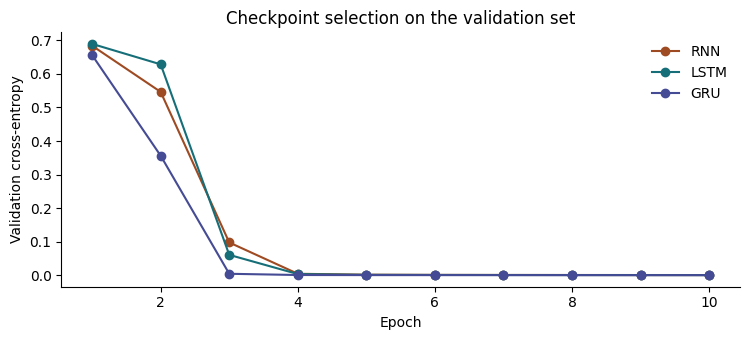

In [7]:
colors = {"RNN": "#9e4a22", "LSTM": "#166e78", "GRU": "#454b94"}
fig, ax = plt.subplots(figsize=(7.6, 3.5))
for name, history in histories.items():
    losses = [loss for loss, _ in history]
    ax.plot(range(1, EPOCHS + 1), losses, marker="o", label=name, color=colors[name])
ax.set(xlabel="Epoch", ylabel="Validation cross-entropy", title="Checkpoint selection on the validation set")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save_result_figure(fig, "validation_loss.png")
plt.show()

## Held-out accuracy at two memory delays

Accuracy is correct predictions divided by all sequences. Standard test tails follow the training range of 2–10 tokens. The long-tail test changes only the neutral-tail length distribution. Both sets contain 128 swapped-order pairs. A constant prediction is an executable instance of the 50% token-count baseline.

In [8]:
test_sets = {"Standard": test, "Long tail": long_test}
results = {"Count baseline": {key: sum(label == 0 for _, label in rows)
                              for key, rows in test_sets.items()}}
for name, model in models.items():
    results[name] = {key: evaluate(model, rows)[1] for key, rows in test_sets.items()}

print(f"{'Model':16}{'Parameters':>12}{'Standard':>18}{'Long tail':>18}")
for name, hits in results.items():
    params = sum(p.numel() for p in models[name].parameters()) if name in models else 0
    formatted = [f"{hits[key]}/{len(rows)} ({hits[key]/len(rows):.1%})" for key, rows in test_sets.items()]
    print(f"{name:16}{params:12}{formatted[0]:>18}{formatted[1]:>18}")

Model             Parameters          Standard         Long tail
Count baseline             0   128/256 (50.0%)   128/256 (50.0%)
RNN                      506  256/256 (100.0%)  256/256 (100.0%)
LSTM                    1754  256/256 (100.0%)   255/256 (99.6%)
GRU                     1338  256/256 (100.0%)  256/256 (100.0%)


Saved outputs/test_accuracy.png


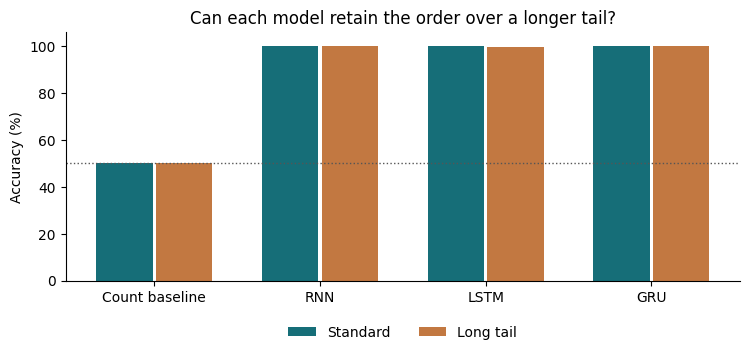

In [9]:
fig, ax = plt.subplots(figsize=(7.6, 3.7))
names = list(results)
for offset, (condition, data), color in zip((-0.18, 0.18), test_sets.items(), ("#166e78", "#c27841")):
    positions = [i + offset for i in range(len(names))]
    ax.bar(positions, [100 * results[n][condition] / len(data) for n in names],
           width=0.34, label=condition, color=color)
ax.axhline(50, color="#555555", linestyle=":", linewidth=1)
ax.set(xticks=range(len(names)), xticklabels=names, ylabel="Accuracy (%)", ylim=(0, 106),
       title="Can each model retain the order over a longer tail?")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2)
fig.tight_layout()
save_result_figure(fig, "test_accuracy.png")
plt.show()

## Inspect a prediction pair

The pair differs only in the order of its signals. The next cell prints each expected label, predicted label, and probability assigned to “red first.” It also checks that adding three padding tokens leaves logits unchanged when true lengths are supplied.

In [10]:
pair = test[:2]
ids, lengths, labels = collate(pair)
with torch.inference_mode():
    for name, model in models.items():
        logits = model(ids, lengths)
        extra_padding = F.pad(ids, (0, 3), value=PAD)
        torch.testing.assert_close(logits, model(extra_padding, lengths))
        probabilities = logits.softmax(dim=-1)
        for (words, label), distribution in zip(pair, probabilities):
            print(f"{name:5} | {' '.join(words)} | expected {LABELS[label]} | "
                  f"predicted {LABELS[distribution.argmax().item()]} | P(red first)={distribution[0]:.3f}")

RNN   | tap hum red ping hum ping blue hum tap tap | expected red first | predicted red first | P(red first)=1.000
RNN   | tap hum blue ping hum ping red hum tap tap | expected blue first | predicted blue first | P(red first)=0.000
LSTM  | tap hum red ping hum ping blue hum tap tap | expected red first | predicted red first | P(red first)=1.000
LSTM  | tap hum blue ping hum ping red hum tap tap | expected blue first | predicted blue first | P(red first)=0.000
GRU   | tap hum red ping hum ping blue hum tap tap | expected red first | predicted red first | P(red first)=1.000
GRU   | tap hum blue ping hum ping red hum tap tap | expected blue first | predicted blue first | P(red first)=0.000


### One error under a longer delay

All three models reached 256/256 on the standard test. On the longer test the RNN and GRU reached 256/256. The LSTM reached 255/256. Inspect the first error below. A single error is too little evidence to rank these cells.

In [11]:
with torch.inference_mode():
    for name, model in models.items():
        for ids, lengths, labels in loader(long_test):
            predictions = model(ids, lengths).argmax(dim=-1)
            errors = (predictions != labels).nonzero().flatten()
            if len(errors):
                row = errors[0].item()
                words = [TOKENS[token] for token in ids[row, :lengths[row]].tolist()]
                last_signal = max(words.index("red"), words.index("blue"))
                print(f"{name} | neutral tokens after the second signal: {len(words)-last_signal-1}")
                print(" ".join(words))
                print(f"Expected {LABELS[labels[row].item()]} | predicted {LABELS[predictions[row].item()]}")
                break

LSTM | neutral tokens after the second signal: 22
ping tap blue ping red tick tick ping ping tap ping tap tap hum ping ping tap tick tap tick hum hum tap ping ping tap ping
Expected blue first | predicted red first


## Other ways to arrange recurrence

**One-to-many** emits a sequence from a single input, as in image captioning. **Many-to-one** maps a sequence to one label, as in the signal task. **Aligned many-to-many** emits one label per input, as in token tagging. An **encoder–decoder** can translate between sequences of different lengths. A decoder begins with a start token and generates until an end token or length limit. Attention can give it access to all encoder states.

A **bidirectional RNN** reads both left-to-right and right-to-left. Its paired states suit offline tagging when the full sequence is available. A causal forecaster must restrict itself to observations available at prediction time. The next cell builds a bidirectional GRU and an encoder–decoder, then performs untrained forward passes to show their output shapes.

In [12]:
with torch.inference_mode():
    torch.manual_seed(SEED)
    ids = encode(example).unsqueeze(0)
    embeddings = nn.Embedding(len(TOKENS), EMBED)(ids)
    bidirectional = nn.GRU(EMBED, WIDTH, batch_first=True, bidirectional=True)
    contextual, _ = bidirectional(embeddings)
    print("Bidirectional tagging features (batch, input steps, 2 x width):", tuple(contextual.shape))

    encoder = nn.GRU(EMBED, WIDTH, batch_first=True)
    decoder = nn.GRU(EMBED, WIDTH, batch_first=True)
    target_vocab = ["<start>", "<end>", "first", "red", "blue"]
    target_embed = nn.Embedding(len(target_vocab), EMBED)
    output_layer = nn.Linear(WIDTH, len(target_vocab))
    _, context = encoder(embeddings)
    # Teacher forcing supplies the preceding target token for each decoder step.
    decoder_input = torch.tensor([[0, 2, 3]])  # <start>, first, red
    decoder_states, _ = decoder(target_embed(decoder_input), context)
    target_logits = output_layer(decoder_states)
    print("Encoder input steps:", ids.shape[1])
    print("Decoder logits (batch, output steps, target vocabulary):", tuple(target_logits.shape))

Bidirectional tagging features (batch, input steps, 2 x width): (1, 6, 32)
Encoder input steps: 6
Decoder logits (batch, output steps, target vocabulary): (1, 3, 5)


## Interpreting the comparison

The exact 50% baseline follows from the paired design. A higher score indicates access to order information. Comparing the two test columns shows how far a model retains that information when more neutral tokens intervene before the readout. Either signal can serve as a cue here because each sequence contains exactly one of each.

These results describe a controlled task with one training seed and a fixed hidden width. The gated models have different parameter counts. A parameter-matched, multi-seed comparison would test whether the same pattern persists. An application such as sentiment classification would also need real examples, a separate test set and analysis of language-specific errors.

## Reading

- Course text: *Chapter 6, Recurrent Neural Networks*, pp. 2–17. Chapter 3, pp. 7–11 and 16, covers loss, validation and unstable gradients. Chapter 4, pp. 8 and 22–23, covers Adam and gradient clipping.
- PyTorch documentation: [RNN](https://docs.pytorch.org/docs/stable/generated/torch.nn.RNN.html), [LSTM](https://docs.pytorch.org/docs/stable/generated/torch.nn.LSTM.html), [GRU](https://docs.pytorch.org/docs/stable/generated/torch.nn.GRU.html), and [packed sequences](https://docs.pytorch.org/docs/stable/generated/torch.nn.utils.rnn.pack_padded_sequence.html).
- Andrej Karpathy, [The Unreasonable Effectiveness of Recurrent Neural Networks](https://karpathy.github.io/2015/05/21/rnn-effectiveness/), 2015. Examples of input and output arrangements.
- Zhang et al., [Backpropagation Through Time](https://d2l.ai/chapter_recurrent-neural-networks/bptt.html) and [The Encoder–Decoder Architecture](https://d2l.ai/chapter_recurrent-modern/encoder-decoder.html), *Dive into Deep Learning*.